# Homework 3

#### Data Preparation 

In [2]:
import pandas as pd
import numpy as np

In [ ]:
df = pd.read_csv('https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv')

df.head()
#df.shape


,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [10]:
#df.isnull().sum()
df.dtypes

lead_source                     str
industry                        str
employment_status               str
location                        str
annual_income               float64
number_of_courses_viewed      int64
interaction_count             int64
lead_score                  float64
converted                     int64
dtype: object

In [11]:
categorical = ['lead_source', 'industry', 'employment_status', 'location']
numerical = ['annual_income', 'number_of_courses_viewed', 'interaction_count', 'lead_score']
target = ['converted']

In [14]:
for c in categorical:
    df[c] = df[c].fillna('NA')

for n in numerical:
    df[n] = df[n].fillna(0.0)

In [15]:
df.isnull().sum()

lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64

#### Question 1

In [ ]:
df.industry.mode()

0    technology
Name: industry, dtype: str

#### Question 2

In [28]:
np.set_printoptions(legacy='1.25')
import seaborn as sns

                          annual_income  number_of_courses_viewed  \
annual_income                      1.00                      0.16   
number_of_courses_viewed           0.16                      1.00   
interaction_count                  0.12                      0.72   
lead_score                         0.23                      0.76   

                          interaction_count  lead_score  
annual_income                          0.12        0.23  
number_of_courses_viewed               0.72        0.76  
interaction_count                      1.00        0.92  
lead_score                             0.92        1.00  


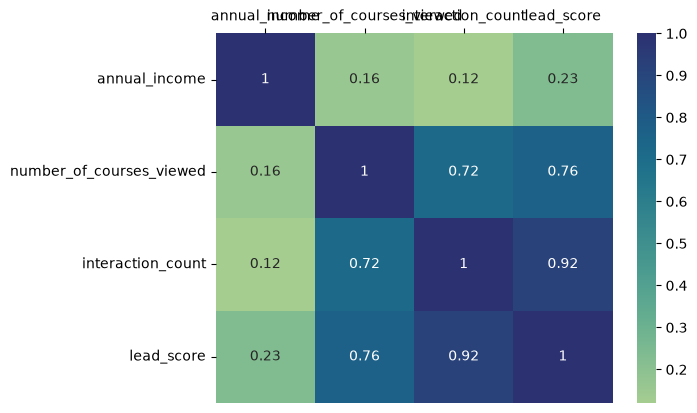

In [37]:
corr_dict = {}

for n in numerical:
    corr_list = []
    for n2 in numerical:
        correlation = df[n].corr(df[n2])
        corr_list.append(round(correlation, 2))
    corr_dict[n] = corr_list

#print(corr_dict)
corr_df = pd.DataFrame(data=corr_dict, index=numerical)
print(corr_df)

plot = sns.heatmap(corr_df, annot=True, cmap="crest")
plot.xaxis.tick_top()



answer = biggest correlation is between interaction_count and lead_score

#### Question 3

In [40]:
from sklearn.model_selection import train_test_split

In [41]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=42)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=42)

df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_train = df_train.converted.values
y_val = df_val.converted.values
y_test = df_test.converted.values

del df_train['converted']
del df_val['converted']
del df_test['converted']

In [45]:
from sklearn.metrics import mutual_info_score

for c in categorical:
    mi = mutual_info_score(y_train, df_train[c])
    print(c, round(mi,3))

lead_source 0.034
industry 0.002
employment_status 0.019
location 0.001


biggest mutual info score = lead_source

#### Question 4

In [54]:
from sklearn.feature_extraction import DictVectorizer

In [55]:
dv = DictVectorizer(sparse=False)

train_dicts = df_train[categorical + numerical].to_dict(orient='records')
X_train = dv.fit_transform(train_dicts)

val_dicts = df_val[categorical + numerical].to_dict(orient='records')
X_val = dv.transform(val_dicts)

dv.get_feature_names_out()
#print(X_train.shape, X_val.shape)

array(['annual_income', 'employment_status=NA',
       'employment_status=employed', 'employment_status=self_employed',
       'employment_status=student', 'employment_status=unemployed',
       'industry=NA', 'industry=education', 'industry=finance',
       'industry=healthcare', 'industry=manufacturing', 'industry=retail',
       'industry=technology', 'interaction_count', 'lead_score',
       'lead_source=NA', 'lead_source=events',
       'lead_source=organic_search', 'lead_source=paid_ads',
       'lead_source=referral', 'lead_source=social_media', 'location=NA',
       'location=africa', 'location=asia', 'location=europe',
       'location=north_america', 'location=south_america',
       'number_of_courses_viewed'], dtype=object)

In [56]:
from sklearn.linear_model import LogisticRegression

In [58]:
model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000, random_state=42)
model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l

In [62]:
print(round(model.score(X_val, y_val),2))
og_accuracy = model.score(X_val, y_val)

0.65


#### Question 5

In [86]:
import pprint
dv = DictVectorizer(sparse=False)
model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000, random_state=42)


features = categorical + numerical
#print(features)

q5_acc = {}
for f in features:

    df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=42)
    df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=42)
    df_train = df_train.reset_index(drop=True)
    df_val = df_val.reset_index(drop=True)
    df_test = df_test.reset_index(drop=True)
    y_train = df_train.converted.values
    y_val = df_val.converted.values
    y_test = df_test.converted.values
    del df_train['converted']
    del df_val['converted']
    del df_test['converted']

    features2 = features.copy()

    del df_train[f]
    del df_val[f]
    features2.remove(f)
    #print(features)
    #print(features2)

    train_dicts = df_train[features2].to_dict(orient='records')
    X_train = dv.fit_transform(train_dicts)

    val_dicts = df_val[features2].to_dict(orient='records')
    X_val = dv.transform(val_dicts)

    model.fit(X_train, y_train)
    acc = round(model.score(X_val, y_val),3)

    key1 = f + ' removed'
    q5_acc[key1] = acc

print("original accuracy: ", og_accuracy)
pprint.pprint(q5_acc)

original accuracy:  0.645
{'annual_income removed': 0.724,
 'employment_status removed': 0.645,
 'industry removed': 0.645,
 'interaction_count removed': 0.601,
 'lead_score removed': 0.644,
 'lead_source removed': 0.642,
 'location removed': 0.645,
 'number_of_courses_viewed removed': 0.643}


In [88]:
diff_lead_source = og_accuracy - q5_acc['lead_source removed']
diff_number_of_courses_viewed = og_accuracy - q5_acc['number_of_courses_viewed removed']
diff_interaction_count = og_accuracy - q5_acc['interaction_count removed']

print('lead_source acc diff: ', diff_lead_source)
print('number_of_courses_viewed diff: ', diff_number_of_courses_viewed)
print('interaction_count diff: ', diff_interaction_count)

lead_source acc diff:  0.0030000000000000027
number_of_courses_viewed diff:  0.0020000000000000018
interaction_count diff:  0.04400000000000004


answer: number_of_courses_viewed has the smallest difference

#### Question 6

In [93]:
dv = DictVectorizer(sparse=False)

df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=42)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=42)

df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_train = df_train.converted.values
y_val = df_val.converted.values
y_test = df_test.converted.values

del df_train['converted']
del df_val['converted']
del df_test['converted']

train_dicts = df_train[categorical + numerical].to_dict(orient='records')
X_train = dv.fit_transform(train_dicts)

val_dicts = df_val[categorical + numerical].to_dict(orient='records')
X_val = dv.transform(val_dicts)

C_list = [0.000001, 0.00001, 0.0001, 0.001]

for c in C_list:
    model = LogisticRegression(solver='liblinear', C=c, max_iter=1000, random_state=42)
    model.fit(X_train, y_train)
    acc = round(model.score(X_val, y_val),3)
    formatted_c = f"{c:.6f}"
    print("C: ", formatted_c, "  --  accuracy: ", acc)



C:  0.000001   --  accuracy:  0.598
C:  0.000010   --  accuracy:  0.598
C:  0.000100   --  accuracy:  0.613
C:  0.001000   --  accuracy:  0.645


answer: 0.001